# Random Forest and ensemble methods — Charis

This continues the all-Part expansion at the end of `data_exploration-2.ipynb`. We predict two continuous values: SBP and DBP. A Random Forest averages predictions from many decision trees.

The input is a table of 37 PPG measurements per window. ABP is used for draft labels and quality checks only. This notebook displays an already-completed run; set the optional switch to train a new run. The test set stays reserved.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image
from random_forest_pipeline import load_data

DATA = Path('outputs/expanded_eda_oct14')
RUN = Path('outputs/random_forest_oct14')
windows, features = load_data(DATA)
training = windows[windows.split.eq('train')]
validation = windows[windows.split.eq('validation')]
X_train = training[features].replace([np.inf, -np.inf], np.nan)
y_train = training[['sbp', 'dbp']]
X_val = validation[features].replace([np.inf, -np.inf], np.nan)
y_val = validation[['sbp', 'dbp']]

print('Training:', X_train.shape, 'Validation:', X_val.shape)
print('Reserved test windows:', windows.split.eq('test').sum())
display(pd.DataFrame({'PPG predictor': features}))
display(windows[windows.eligible].groupby(['part', 'split']).agg(
    windows=('window_key', 'size'), recordings=('record_key', 'nunique')))

Training: (4013, 37) Validation: (857, 37)
Reserved test windows: 882


,PPG predictor
0,ppg_raw_mean
1,ppg_raw_std
2,ppg_raw_iqr
3,ppg_raw_skew
4,ppg_raw_kurtosis
5,ppg_raw_p05
6,ppg_raw_p95
7,ppg_clean_mean
8,ppg_clean_std
9,ppg_clean_iqr


windows  recordings
part   split                          
Part_1 test            217          23
       train           911         110
       validation      207          26
Part_2 test            268          28
       train          1101         119
       validation      234          24
Part_3 test            179          23
       train           953         119
       validation      204          26
Part_4 test            218          26
       train          1048         119
       validation      212          24

**How the forest is built**

Each tree learns rules from a bootstrap sample of training windows. At each split, it considers a random subset of features. The forest averages the trees' predictions. This is regression, so we use `RandomForestRegressor`.

We replace rare missing feature values with a training median. SBP and DBP are standardized inside training so their different scales do not dominate the shared tree splits. Predictions are converted back to mmHg automatically. The example below shows the selected model's structure; it does not fit anything yet.

In [2]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

forest = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('forest', RandomForestRegressor(
        n_estimators=200, max_depth=10, min_samples_leaf=5,
        max_features=0.8, random_state=20261014, n_jobs=2,
    )),
])
model_example = TransformedTargetRegressor(
    regressor=forest, transformer=StandardScaler())
model_example

TransformedTargetRegressor(regressor=Pipeline(steps=[('imputer',
                                                      SimpleImputer(strategy='median')),
                                                     ('forest',
                                                      RandomForestRegressor(max_depth=10,
                                                                            max_features=0.8,
                                                                            min_samples_leaf=5,
                                                                            n_estimators=200,
                                                                            n_jobs=2,
                                                                            random_state=20261014))]),
                           transformer=StandardScaler())

**Choose settings using grouped training folds**

We tried four configurations: maximum depth 10/unlimited and minimum leaf size 5/10. Each was checked on three training folds. Entire overlap groups stay together, so nearby windows from the same recording cannot appear on both sides of a fold. Imputation and scaling are refitted inside each fold.

The chosen configuration had depth 10 and minimum leaf size 5. Selection used the average SBP/DBP MAE over training folds; the outer validation and test sets did not tune the forest. We do not use OOB error as a replacement for grouped evaluation.

The other models are a training-mean predictor, Ridge (alpha 10), and a predefined Extra Trees ensemble. Extra Trees chooses more randomized split thresholds. It was not separately tuned.

In [3]:
settings = json.loads((RUN / 'model_settings.json').read_text())
print('Selected RF settings:', settings['rf_best_params'])
print('Grouped training CV mean SBP/DBP MAE:', round(settings['rf_grouped_cv_mae'], 3))
cv_results = pd.read_csv(RUN / 'random_forest_cv_results.csv')
display(cv_results[['param_regressor__forest__max_depth',
    'param_regressor__forest__min_samples_leaf', 'mean_test_score',
    'std_test_score', 'rank_test_score']].sort_values('rank_test_score'))
print('CV scores are negative MAE: closer to zero is better.')
folds = pd.read_csv(RUN / 'training_grouped_cv_assignments.csv')
assert folds.groupby('overlap_group').cv_validation_fold.nunique().max() == 1
display(folds.groupby('cv_validation_fold').agg(
    windows=('window_key','size'), overlap_groups=('overlap_group','nunique')))

Selected RF settings: {'regressor__forest__max_depth': 10, 'regressor__forest__min_samples_leaf': 5}
Grouped training CV mean SBP/DBP MAE: 11.931


,param_regressor__forest__max_depth,param_regressor__forest__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,10.0,5,-11.930591,0.483874,1
2,NaN,5,-11.932058,0.524844,2
3,NaN,10,-11.977769,0.487266,3
1,10.0,10,-11.978368,0.467415,4


CV scores are negative MAE: closer to zero is better.


,windows,overlap_groups
cv_validation_fold,,
0,1338,155
1,1338,156
2,1337,155


**Optional new training run**

Run All keeps this switch off and reads the saved results. If you turn it on, use a new output folder. The runner repeats grouped training CV, fits all four models and reports validation errors; it does not score the reserved test set.

In [4]:
RUN_TRAINING = False
if RUN_TRAINING:
    from random_forest_pipeline import train
    train(DATA, Path('outputs/random_forest_new_run'), seed=20261014)
else:
    print('Using the saved October 14 run.')

Using the saved October 14 run.


**Validation results**

MAE is the average size of the error in mmHg; RMSE gives larger errors more weight. The mean baseline predicts the training-average pressure for every window.

Window MAE weights every window equally. Recording-macro MAE first averages errors within each recording, then weights recordings equally. The overlap-group bootstrap resamples detected groups, not individual windows. It still cannot establish patient independence.

,model,target,windows,records,overlap_groups,mae_mmHg,rmse_mmHg,bias_mmHg,error_sd_mmHg,recording_macro_mae,overlap_group_macro_mae
0,Training mean,sbp,857,100,100,18.696,23.432,-2.007,23.360,18.353,18.353
1,Training mean,dbp,857,100,100,10.031,13.264,-3.029,12.921,10.446,10.446
2,Ridge,sbp,857,100,100,17.120,22.260,-1.058,22.248,16.845,16.845
3,Ridge,dbp,857,100,100,8.873,12.270,-3.385,11.801,9.428,9.428
4,Random Forest,sbp,857,100,100,16.861,22.436,-0.794,22.435,16.360,16.360
5,Random Forest,dbp,857,100,100,8.835,12.156,-3.095,11.762,9.169,9.169
6,Extra Trees,sbp,857,100,100,16.956,22.454,-0.812,22.453,16.213,16.213
7,Extra Trees,dbp,857,100,100,8.689,11.967,-3.098,11.566,9.077,9.077


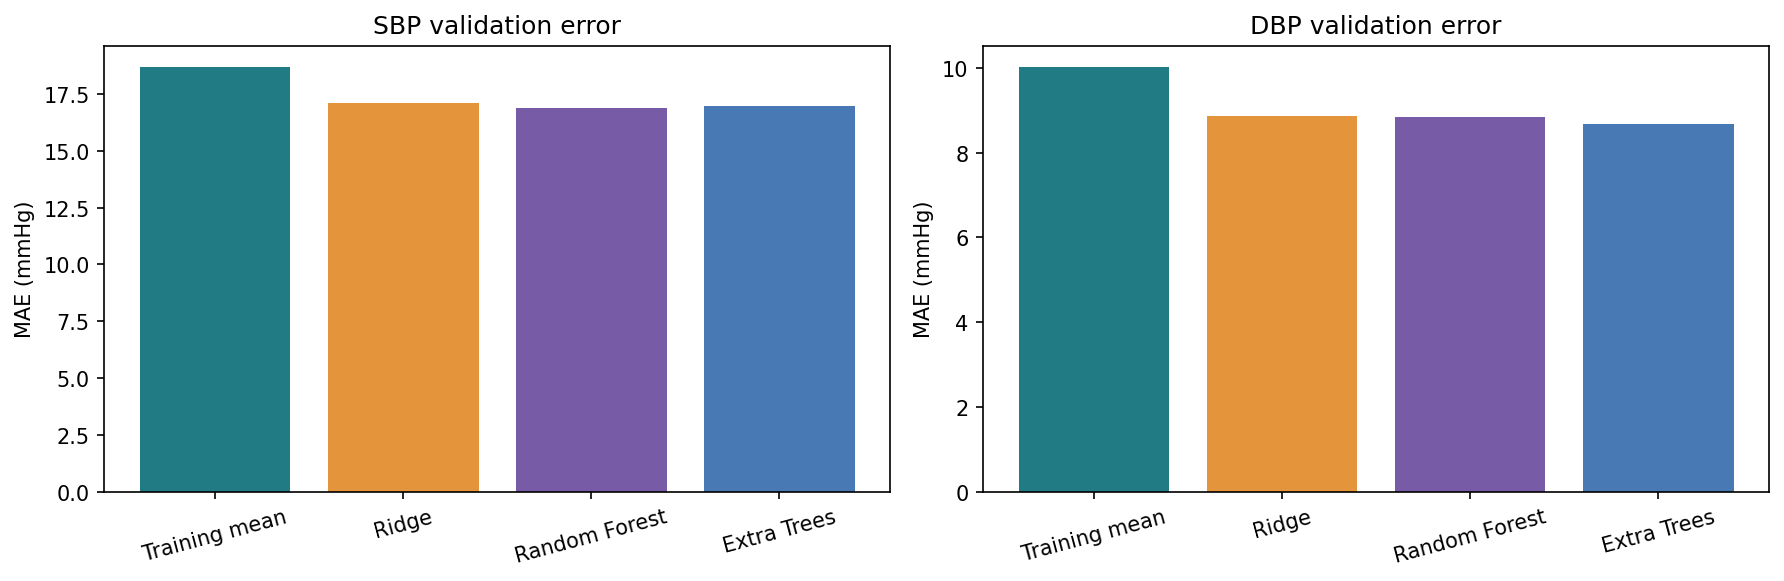

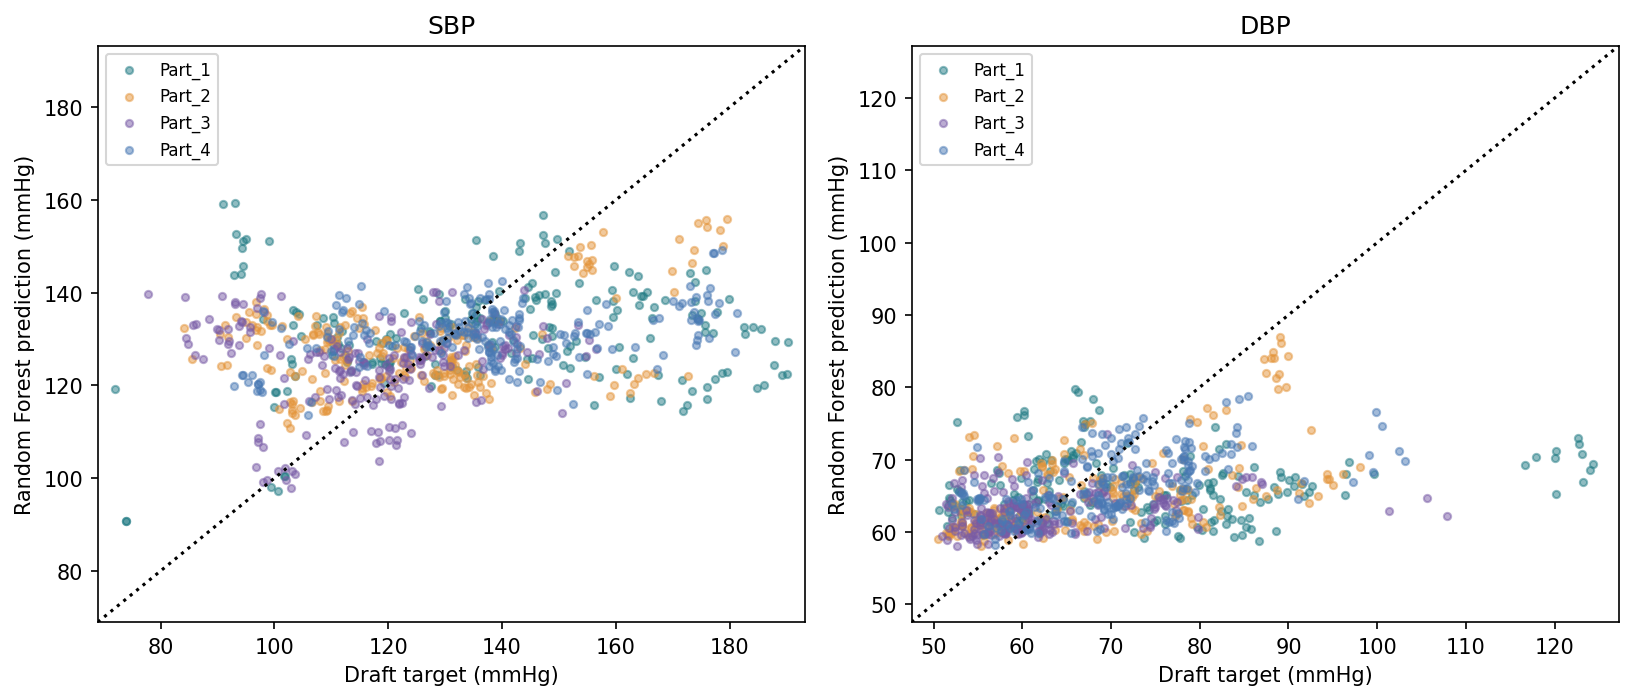

,model,target,windows,records,overlap_groups,mae_mmHg,rmse_mmHg,bias_mmHg,error_sd_mmHg,recording_macro_mae,overlap_group_macro_mae,part
16,Random Forest,sbp,207,26,26,22.046,28.876,-7.206,28.030,22.277,22.277,Part_1
17,Random Forest,dbp,207,26,26,13.313,17.793,-6.526,16.593,12.727,12.727,Part_1
18,Random Forest,sbp,234,24,24,15.236,19.555,3.054,19.356,13.777,13.777,Part_2
19,Random Forest,dbp,234,24,24,8.350,10.474,-2.136,10.276,8.629,8.629,Part_2
20,Random Forest,sbp,204,26,26,14.195,19.749,6.539,18.680,13.222,13.222,Part_3
21,Random Forest,dbp,204,26,26,6.634,9.091,0.010,9.113,7.541,7.541,Part_3
22,Random Forest,sbp,212,24,24,16.156,20.577,-5.837,19.778,15.932,15.932,Part_4
23,Random Forest,dbp,212,24,24,7.115,9.362,-3.793,8.579,7.617,7.617,Part_4


,model,target,overlap_groups,group_macro_mae,mae_ci_low,mae_ci_high,gain_over_mean_baseline,gain_ci_low,gain_ci_high
0,Extra Trees,sbp,100,16.213,13.617,18.811,2.139,0.515,3.781
1,Random Forest,sbp,100,16.360,13.728,18.957,1.993,0.429,3.752
2,Ridge,sbp,100,16.845,14.410,19.426,1.508,-0.130,3.045
3,Training mean,sbp,100,18.353,15.778,21.035,0.000,0.000,0.000
4,Extra Trees,dbp,100,9.077,7.525,10.824,1.369,0.648,2.133
5,Random Forest,dbp,100,9.169,7.607,10.860,1.278,0.578,2.021
6,Ridge,dbp,100,9.428,7.737,11.209,1.018,0.346,1.750
7,Training mean,dbp,100,10.446,8.886,12.174,0.000,0.000,0.000


In [5]:
comparison = pd.read_csv(RUN / 'validation_model_comparison.csv')
display(comparison.round(3))
display(Image(filename=str(RUN / 'validation_model_comparison.png')))
display(Image(filename=str(RUN / 'random_forest_predictions.png')))
display(pd.read_csv(RUN / 'validation_metrics_by_part.csv').query('model == "Random Forest"').round(3))
display(pd.read_csv(RUN / 'validation_group_bootstrap.csv').round(3))

**Which PPG features helped?**

Permutation importance shuffles one feature in validation and measures how much the average SBP/DBP MAE increases. A larger increase suggests the fitted model used that feature. Correlated features can share information, and negative values can occur. The error bars show variation across five shuffles, not statistical confidence intervals.

We also save training impurity importance for comparison, but neither measure establishes physiology or causation. No feature is selected or removed based on this validation plot in the current run.

,feature,validation_permutation_mae_increase,permutation_repeat_sd,training_impurity_importance
0,vpg_skew,0.4708,0.0616,0.0653
1,ppg_hr_bpm,0.4065,0.0477,0.1064
2,apg_p95,0.3245,0.0503,0.0532
3,apg_iqr,0.2987,0.0441,0.0734
4,vpg_kurtosis,0.2083,0.0064,0.0425
5,apg_skew,0.1846,0.0269,0.0487
6,vpg_iqr,0.1212,0.0098,0.0358
7,ppg_high_frequency_fraction,0.0983,0.0272,0.0575
8,ppg_raw_kurtosis,0.0720,0.0201,0.0340
9,apg_std,0.0567,0.0120,0.0200


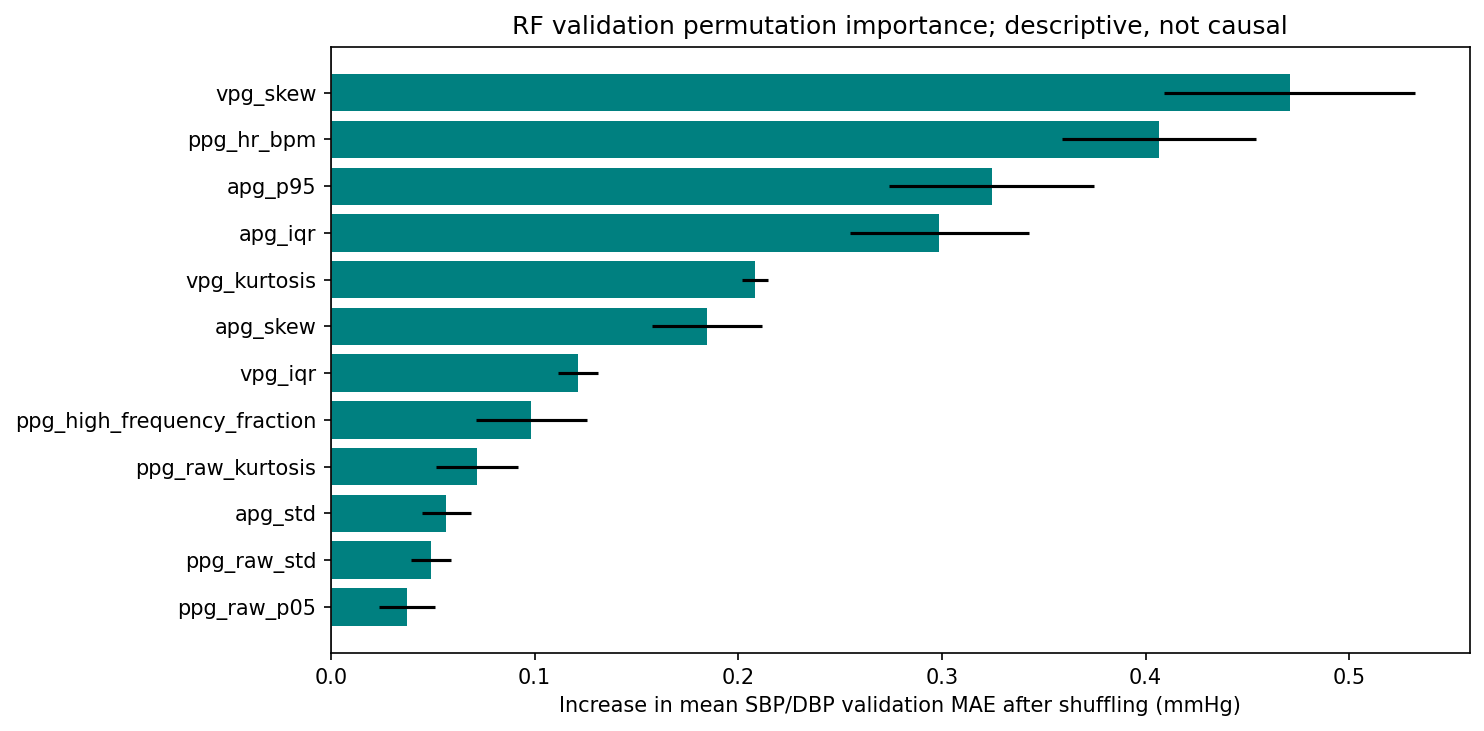

Reloaded RF reproduces the saved validation predictions.


In [6]:
importance = pd.read_csv(RUN / 'random_forest_feature_importance.csv')
display(importance.head(12).round(4))
display(Image(filename=str(RUN / 'random_forest_feature_importance.png')))
# Load our own saved model and reproduce validation predictions.
model = joblib.load(RUN / 'random_forest.joblib')
predicted = model.predict(X_val)
saved = pd.read_csv(RUN / 'validation_predictions.csv').query('model == "Random Forest"')
np.testing.assert_allclose(predicted, saved[['prediction_sbp','prediction_dbp']].to_numpy())
print('Reloaded RF reproduces the saved validation predictions.')

**Interpretation and resources**

RF validation MAE is about 16.86/8.84 mmHg for SBP/DBP, compared with 18.70/10.03 for the mean baseline. Ridge and Extra Trees are close; Extra Trees has slightly lower DBP error in this run. These are preliminary all-Part validation results under provisional label/quality gates. The reserved test set is not scored.

The RF errors cannot be directly compared with the earlier ResNet pilot because the data, sample size and quality rules differ. A fair comparison requires the same reviewed rows and split. ABP-based checks are retrospective training-label checks, not something available when predicting from PPG alone.

Read `RANDOM_FOREST_RESOURCES.md` for the papers, ensemble guide, tutorials and access limitations. Read `EXPANDED_EDA_RF_RESULTS.md` for the coach-feedback response and saved figures. Remaining work includes representative manual review across Parts, near-overlap/patient-identity limitations, filter sensitivity, and a final fixed evaluation protocol.

**Where the model misses**

The validation predictions stay close to the middle of the pressure range. For SBP below 100 mmHg, the RF averaged 129 mmHg; at 160 mmHg and above, it averaged 134 mmHg. For DBP at 90 mmHg and above, it averaged 68 mmHg when the references averaged 102 mmHg. The model improves on the mean baseline in some extreme bands, but errors there remain large. This pattern is a reason to call the first result modest, not ready for practical blood-pressure use.

The following breakdown uses the validation set only. Each range includes repeated windows from some recordings, so the counts are not counts of independent people.

In [ ]:
from IPython.display import display, Image
error_by_band = pd.read_csv(RUN / 'validation_error_by_pressure_band.csv')
display(error_by_band.pivot_table(index=['target', 'pressure_band'], columns='model', values=['windows', 'mae_mmHg', 'bias_mmHg']).round(2))
display(Image(filename=str(RUN / 'validation_error_by_pressure_band.png')))
display(Image(filename=str(RUN / 'validation_rf_predictions_scatter.png')))

**Additional model check: RBF SVR**

The supplied reading includes other feature-based regressors, so I also tested an RBF support vector regressor (SVR). Its settings were selected using three grouped folds from training data only, then measured on the same validation set as the forest. SVR scored 17.03 mmHg SBP MAE and 9.03 mmHg DBP MAE. That is close, but slightly behind Random Forest on both targets and behind Extra Trees on DBP. It does not change the current conclusion: the feature models improve only modestly over the mean baseline.

The grouped training-fold mean multi-target MAE for the selected SVR was 11.88 mmHg. The reserved test set remains unused. Histogram gradient boosting was considered but its local grouped search was stopped because it was taking substantially longer; it has no result in this comparison.

In [ ]:
SVR_RUN = Path('outputs/svr_grouped_oct14')
svr_settings = json.loads((SVR_RUN / 'settings.json').read_text())
print('SVR settings chosen in grouped training folds:', svr_settings['best_params'])
print('Grouped training-fold mean MAE:', round(svr_settings['grouped_training_cv_mae'], 2), 'mmHg')
display(pd.read_csv(SVR_RUN / 'validation_metrics.csv').round(2))
display(pd.read_csv(SVR_RUN / 'grouped_training_cv.csv')[[
    'param_regressor__model__estimator__C',
    'param_regressor__model__estimator__epsilon',
    'mean_test_score', 'std_test_score']].round(3))

**Did a wider RF search help?**

I expanded the grouped training search to 27 combinations of tree depth, minimum leaf size and features considered at each split. The selected forest was shallower and used smaller leaves, but its validation MAE changed only from 16.86 to 16.91 mmHg for SBP and from 8.83 to 8.88 mmHg for DBP. A paired bootstrap over the 100 validation overlap groups found no clear gain over the original forest. I keep the original RF as the simpler reference; more hyperparameter tuning is unlikely to be the main fix.

The next larger gains are more likely to come from reviewing ABP-derived labels and improving the PPG feature/window representation. At the time of this tuning run, the test set was unused. The October 28 test results appear below.

In [ ]:
TUNE_RUN = Path('outputs/rf_tuning_oct14')
tune_settings = json.loads((TUNE_RUN / 'settings.json').read_text())
print('Selected grouped-CV settings:', tune_settings['best_params'])
print('Grouped training-CV MAE:', round(tune_settings['grouped_training_cv_mae'], 2), 'mmHg')
display(pd.read_csv(TUNE_RUN / 'validation_metrics.csv').round(2))
display(pd.read_csv(TUNE_RUN / 'paired_group_bootstrap_vs_original_rf.csv').round(3))

# Completed Random Forest and ensemble comparison

October 28, 2026. The RF/ensemble experiment is complete for the current frozen feature dataset. The test results are now available; the October 14 files still describe the earlier validation run.

## Final test results

Errors below are in mmHg on 882 test windows from 100 recordings / 100 detected overlap groups across Parts 1–4. Training used 4,013 windows; validation used 857. These are recording/overlap-group splits, not confirmed independent patients.

| Model | SBP MAE | DBP MAE | SBP RMSE | DBP RMSE |
|---|---:|---:|---:|---:|
| Training mean | 19.56 | 8.21 | 23.04 | 10.59 |
| Random Forest | 19.00 | 7.72 | 23.73 | 9.71 |
| Extra Trees | 18.60 | 7.69 | 23.34 | 9.66 |
| Histogram boosting | 19.34 | 7.61 | 23.74 | 9.61 |
| Equal-weight ensemble | 18.91 | 7.61 | 23.48 | 9.56 |

Extra Trees has the lowest observed SBP MAE. The equal-weight ensemble has the lowest observed DBP MAE, virtually tied with boosting (7.608 versus 7.609 before rounding). The differences are small, so there is no clear winner. RF improves MAE over the mean baseline by only 0.56 mmHg SBP and 0.49 mmHg DBP; its SBP RMSE is worse than baseline. When we resampled the test recording groups, the 95% intervals for each model’s improvement over baseline included zero. The models therefore show only a small improvement over predicting the training average.

## What we ran

- Reused the frozen October 14 RF and Extra Trees training checkpoints after verifying dataset fingerprints. Their validation metrics reproduce the saved results.
- Completed histogram gradient boosting: four configurations on three grouped training folds, with separate target regressors, training-fold target scaling and native missing-value handling. Selected seven leaves and L2 regularization 10. Fixed 150 iterations, learning rate 0.05, minimum leaf size 20; early stopping disabled to avoid an internal ungrouped validation split.
- Added a predefined arithmetic average of RF, Extra Trees and boosting, with one-third weights. No validation/test weight fitting.
- Wrote the protocol before generating test predictions. Reported every frozen candidate on validation and test, with per-Part metrics and 2,000 paired overlap-group bootstrap resamples. No refitting or tuning followed test scoring.
- Existing five data/split/quality tests passed. Runtime checks confirmed original validation reproduction, finite predictions, and dataset fingerprints; existing loader checks prevent known identity overlap across splits.

## Files and reproduction

`finish_ensemble_comparison.py` reproduces the run. Set OMP_NUM_THREADS=2 and OPENBLAS_NUM_THREADS=2; run with `.venv/bin/python`. Its output directory must not already exist, so archive/copy the current results and change OUT for any new run. The current test has now been examined and must not become a tuning set for later experiments.

`outputs/ensemble_final_oct28/` contains the protocol, selected boosting settings, fitted boosting checkpoint, CV scores, validation/test predictions, metrics, per-Part breakdowns and bootstrap intervals. RF and Extra Trees checkpoints remain in `outputs/random_forest_oct14/`. To reproduce the equal-weight predictor, average those two checkpoints' predictions and the new boosting checkpoint's predictions on the same ordered feature whitelist in protocol.json. All three return mmHg.

## What the results mean

The comparison is finished, but the errors are still too large to call the model accurate. Labels and signal-quality gates remain provisional, and patient identities and undetected overlaps remain unresolved. Further gains likely require reviewing labels/features and pressure-range coverage. Any later model development needs a new untouched evaluation dataset or a rigorously specified new evaluation design; these test results cannot be used to tune and still count as an untouched final test.
